# Component B, Question 4: Ethics, Risk and Responsible Autonomy

This discussion draws on **evidence from this project's own experiments**
(Components A and B) wherever possible, so that each risk is illustrated by
something that actually happened in simulation. The table below gathers the
measured evidence, then each required topic is discussed in turn.

In [1]:
import sys
sys.path.append("..")
from pathlib import Path
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import swarm_data as sd

OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110})

In [2]:
import json
summ = sd.summary()


metrics = {k: pd.DataFrame([sd.run_metrics(r) for r in sd.runs(k)])
           for k in sd.KINDS + ["distributed_nn"] if sd.runs(k)}


def gbest(kind):
    return f"{metrics[kind]['gbest error (cm)'].mean():.1f} cm"


evidence = [
    ("Robots invisible to each other's LiDAR (first swarm version)",
     "Repeated robot-robot collisions until collars were added", "B1"),
    ("Symmetric deadlock between two robots",
     "Robots froze facing each other until a tie-break rule and commitment "
     "layer were added", "B1"),
    ("Coordinator failure (centralised)",
     f"mean gbest error {gbest('centralised_coordinator_failure')} vs "
     f"{gbest('centralised')} normally (3 seeds)", "B3"),
    ("Robot failure (distributed)",
     f"survivors' mean gbest error {gbest('distributed_robot_failure')} "
     f"vs {gbest('distributed')} normally (3 seeds)", "B3"),
]
if "distributed_nn" in metrics:
    agree = []
    for run in sd.runs("distributed_nn"):
        for i in range(sd.N_ROBOTS):
            d = sd.robot_log(run, i)
            d = d[d.action.isin(["FORWARD", "LEFT", "RIGHT"])]
            agree.append((d.action == d.expert_action).mean())
    evidence.append(("Neural network driving (behavioural cloning)",
                     f"agrees with its teacher {np.mean(agree):.0%} of the time "
                     "while driving, similar to offline; tested only in the "
                     "training arena", "B3"))
evidence += [
    ("Camera textures failed to download (Component A)",
     "Unlit images: colour detection failed until the world was rebuilt", "A-Q1"),
    ("Wheel odometry (Component A)",
     "about 14 cm drift over a 2 m route, against about 2 cm obstacle clearance", "A-Q4"),
]
pd.DataFrame(evidence, columns=["Observation", "Measured effect", "Where"])

,Observation,Measured effect,Where
0,Robots invisible to each other's LiDAR (first ...,Repeated robot-robot collisions until collars ...,B1
1,Symmetric deadlock between two robots,Robots froze facing each other until a tie-bre...,B1
2,Coordinator failure (centralised),mean gbest error 20.2 cm vs 6.0 cm normally (3...,B3
3,Robot failure (distributed),survivors' mean gbest error 4.3 cm vs 4.7 cm n...,B3
4,Neural network driving (behavioural cloning),agrees with its teacher 97% of the time while ...,B3
5,Camera textures failed to download (Component A),Unlit images: colour detection failed until th...,A-Q1
6,Wheel odometry (Component A),"about 14 cm drift over a 2 m route, against ab...",A-Q4


## 1. Bias and reliability risks in sensor data, simulation assumptions and learned models

**Sensor data.** Every perception step relied on assumptions that held only
in this world. The camera pipeline (Component A) identified landmarks by
colour thresholds tuned to saturated red, green and blue under controlled
light. When textures failed to download, the images became almost black and
detection failed completely. Real sensors fail in similar *systematic* ways:
glare, darkness, rain, dust, and dark or reflective surfaces that LiDAR
returns poorly. Systematic errors are more dangerous than random noise
because they do not average out, and they can fall unevenly on particular
people and situations. A detector tuned on certain clothing, skin tones,
mobility aids or body sizes may perform worse on others. The swarm's first
version is a concrete example: the LiDAR plane sat above the other robots'
bodies, so they were invisible. A person or pet below that plane, such as a
crawling child or a dog, would be invisible in exactly the same way.

**Simulation assumptions.** The simulation is cleaner than reality: perfect
GPS and compass, no wheel slip, no radio dropouts, a static arena, and a
smooth single-peaked signal. Each assumption flatters the results. The
odometry test in Component A shows the size of the gap. Without the
simulator's perfect pose, drift (about 14 cm) far exceeded the safety margin
(about 2 cm). A real gas plume is also patchy and wind-blown, which would make
PSO's fitness readings far less reliable. Results from this project should be
read as an **upper bound** on real-world performance (the *sim-to-real gap*).

**Learned models.** The network was trained on about 200,000 decisions, all
from *one arena, one teacher and twelve runs*. Its training data contains the
teacher's biases, for example always turning left when undecided, and nothing
outside that world. Within that world it performed well, matching the rule
about 96–97% of the time both offline and while driving. But that only shows
it works *where it was trained*. A model can score well on a test set drawn
from the same conditions and still behave unpredictably when the conditions
change. Evaluation must therefore include closed-loop testing in conditions
that differ from training.

## 2. Transparency and explainability of neural-network decisions

The hand-written rule is fully transparent: its 10 lines can be read and
checked, and every decision traced to a threshold. The network that replaced
it computes each decision through about 2,800 weights, and none of them has a
meaning by itself. When it turns the wrong way, there is no line of code to
point to. Explainability tools give a *partial* view. Permutation importance,
below, measures how much accuracy drops when each input is scrambled.

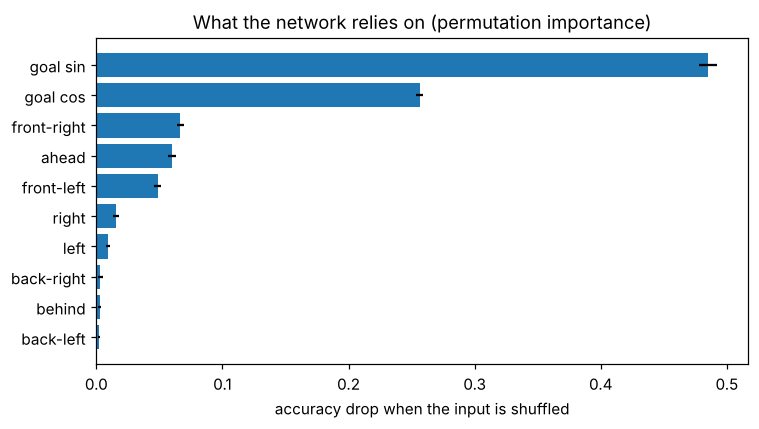

In [3]:
from sklearn.inspection import permutation_importance
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

CLASSES = ["FORWARD", "LEFT", "RIGHT"]
frames = []
for e in sd.BASE_EXPERIMENTS:
    for i in range(sd.N_ROBOTS):
        d = sd.robot_log(e, i)
        frames.append(d[d.expert_action.isin(CLASSES)].assign(
            seed=int(e.rsplit("_s", 1)[1])))
data = pd.concat(frames, ignore_index=True)
data["sin_bearing"] = np.sin(data.bearing)
data["cos_bearing"] = np.cos(data.bearing)
features = sd.SENSOR_COLS + ["sin_bearing", "cos_bearing"]
test = (data.seed == 1).values
X, y = data[features].values, data.expert_action.values
scaler = StandardScaler().fit(X[~test])
model = MLPClassifier((64, 32), max_iter=400, early_stopping=True,
                      n_iter_no_change=20, random_state=0)
model.fit(scaler.transform(X[~test]), y[~test])

sample = np.random.default_rng(0).choice(np.where(test)[0], 4000,
                                         replace=False)
imp = permutation_importance(model, scaler.transform(X[sample]), y[sample],
                             n_repeats=5, random_state=0)
names = ["ahead", "front-left", "left", "back-left", "behind",
         "back-right", "right", "front-right", "goal sin", "goal cos"]
order = np.argsort(imp.importances_mean)
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(np.array(names)[order], imp.importances_mean[order],
        xerr=imp.importances_std[order])
ax.set_xlabel("accuracy drop when the input is shuffled")
ax.set_title("What the network relies on (permutation importance)")
plt.tight_layout()
plt.savefig(OUT_DIR / "b4_permutation_importance.png", bbox_inches="tight")
plt.show()

The network relies mostly on the **goal direction** and the **forward-facing
sectors**, and barely on the sectors behind it. That matches the rule and is
reassuring. The plot also exposes an inherited bias: the front-*right* sector
matters more than the front-*left*. This mirrors the teacher's convention of
turning left unless the right side is *clearly* more open, so the network
mainly needs to check the right side. The network has learned the teacher's
asymmetry, and the explanation tool made it visible. That is exactly the kind
of hidden bias an audit should look for. But the analysis only says *which* inputs matter on average, not
*why* a particular decision was made, and it says nothing about behaviour in
situations missing from the data. For a safety-critical robot, this supports
three practical measures:
1. **Keep an interpretable safety layer** around the learned component. In this project, the commitment and collision-avoidance layer is simple enough to verify by inspection, and the network can only choose actions within it.
2. **Log decisions with their inputs** (as every controller here does), so incidents can be reconstructed and audited.
3. **Prefer interpretable models where performance allows.** A shallow decision tree could likely reproduce this rule almost exactly, with explanations a person can read.

## 3. Risks of autonomous decision-making in safety-critical and human-shared environments

- **Emergent behaviour is hard to predict.** No robot was programmed to crowd together, yet PSO drew all four towards the same point, and in early versions they collided or deadlocked there. Emergent group behaviour is the strength of swarms, but it also means system-level failures can arise from individually correct agents. These can only be found by testing the *group*, not each robot alone.
- **Deadlocks and livelocks.** Two robots facing each other froze indefinitely until a tie-break convention was added. In a hospital corridor or a mine tunnel, a robot frozen in a doorway can block an evacuation route.
- **Wrong or malicious information spreads.** Robots trust the best value their neighbours report. A single faulty sensor, or a compromised robot reporting an extreme reading, would pull the whole swarm towards a false location. In search and rescue, that means searching the wrong area while someone waits. Mitigations include plausibility checks (a reading must be consistent with neighbours' readings and physics), reputation weighting, and message authentication.
- **Human-shared spaces.** None of the controllers here model people. Deployment around people needs person detection all around the robot, speed and force limits that depend on distance (standards for collaborative and mobile robots, such as ISO 3691-4, exist for this reason), and predictable, legible motion so people can anticipate what the robot will do.
- **Accountability.** When a learned, distributed system causes harm, responsibility is spread across the training-data author, the model developer, the integrator and the operator. Clear ownership, documented limits ("not validated near people") and audit logs are preconditions for deployment.

## 4. Fault tolerance, robustness and failure-mode mitigation in multi-agent systems

The failure experiments show the central design trade-off directly:

| Failure mode | Observed effect | Mitigation |
|---|---|---|
| Coordinator fails (centralised) | Shared knowledge lost: error several times larger, swarm never fully converges | Avoid single points of failure; use distributed coordination, or replicate the coordinator with leader re-election |
| Robot fails (distributed) | Ring becomes a line; survivors are just as accurate | Choose topologies that stay connected when one node fails (2-connected graphs such as rings) |
| All robots converge on one point | Crowding: robots compete for the same space (closest bodies about 1.5 cm apart) | Spread targets (e.g. local bests or formation offsets); repulsion between agents |
| Silent failure (robot alive but broken) | Not tested; neighbours would keep using stale or wrong data | Heartbeat messages with time-outs; treat silence as failure |
| Robots invisible to each other | Collisions | Make agents mutually detectable (collars, beacons); redundant sensing |
| Symmetric deadlock | Robots freeze | Symmetry-breaking conventions (always turn left); commitment; time-outs that trigger a recovery manoeuvre |
| Learned policy outside its training data | Untested: only the training arena was used | A verifiable safety layer around the network; testing in unseen environments; DAgger-style retraining; monitor how unusual the inputs are |

A general principle follows: **design for graceful degradation**. Losing one
component should reduce performance, not cause total failure. And the system
should fail into a *safe state* (stop, signal, wait for help), never into an
unknown one.

## 5. Responsible AI and robotics deployment in South Africa

- **Policy direction.** South Africa's Department of Communications and Digital Technologies (DCDT) published a National AI Policy Framework in 2024. On 10 April 2026, it released a **Draft National AI Policy** for public comment, proposing a phased, risk-based approach: unacceptable-risk uses first, then high-risk ones (Bowmans, 2026). Autonomous robots working near people, or in emergency response, would plausibly be treated as high-risk, which makes the testing, documentation and oversight practices above directly relevant.
- **Privacy: POPIA.** Robots with cameras collect images of people, which are personal information under the Protection of Personal Information Act 4 of 2013. Deployments must limit collection to what the task needs, secure the data, and be open about recording. One option is to process images on the robot and store only detections, not raw video.
- **Infrastructure reliability.** Load-shedding and patchy network coverage are real operating conditions in South Africa. Here the experimental finding has practical weight: a swarm that depends on a central server or cloud link fails when power or connectivity does, while a distributed swarm that communicates peer to peer keeps working. Robots should also run on-board, not cloud-dependent, control, and fail safe when power is low.
- **Mining and rescue.** Underground mining is a natural application, for gas detection and search after incidents, much like this project's search task. It falls under the Mine Health and Safety Act 29 of 1996. Robots here could *reduce* human exposure to danger, but only if they are validated for dust, darkness and lost communications, conditions this simulation did not model.
- **Employment.** South Africa's official unemployment rate was 33.6% in the second quarter of 2026 (Statistics South Africa, 2026). Automation that replaces jobs therefore carries particular social weight. Responsible deployment favours uses that *remove people from danger* (inspection, rescue) or create skilled work (maintaining and supervising robots), paired with re-skilling, over uses that only cut labour costs.
- **Local relevance of data.** Models trained abroad, or only in simulation, reflect conditions that may not match local environments: informal settlements, unpaved terrain, different lighting and dust. Local data collection and testing, with consent, should come before deployment.

## Summary

The experiments show, in miniature, the main risks of autonomous multi-agent
systems: perception that fails systematically, learned models that degrade
outside their training data, emergent group failures, and single points of
failure. They also show the mitigations: verifiable safety layers, graceful
degradation through distributed design, symmetry-breaking and commitment, and
thorough logging. In the South African context, robustness to power and
network outages, compliance with POPIA, and a focus on augmenting rather than
displacing workers are especially important.

### References (Harvard)
- Bowmans (2026) *South Africa: Draft National Artificial Intelligence Policy published for public comment*. Available at: https://bowmanslaw.com/insights/south-africa-draft-national-artificial-intelligence-policy-published-for-public-comment/ (Accessed: 24 October 2026).
- Republic of South Africa (1996) *Mine Health and Safety Act 29 of 1996*. Pretoria: Government Printer.
- Republic of South Africa (2013) *Protection of Personal Information Act 4 of 2013*. Pretoria: Government Printer.
- Statistics South Africa (2026) *Quarterly Labour Force Survey, Quarter 2: 2026*, as reported in SAnews (2026) *SA official unemployment rate rises to 33.6%*, 11 August. Available at: https://www.sanews.gov.za/south-africa/sa-official-unemployment-rate-rises-336 (Accessed: 24 October 2026).